# **Regression Practical Exercise Walkthrough**

The aim for this exercise, and the practical exercises going forward, is not just whether you can implement a particular model or algorithm. AI today, or in 2+ years when you graduate, can already implement many of these models if you ask it to. What I want you to come away from this course with is an understanding of how to analyse a dataset, draw conclusions, implement a model based on those conclusions, and then iterate.

Here I would like to walk you through one possible way of analysing the data and making improvements to a regression model. Some of you had some very informative plots, however, either did not make conclusions from these or didn't use those conclusions in your model.

**One thing to keep in mind:** this is a walkthrough of *one possible* exploratory process, not the only correct model. We are going to make hypotheses based on plots, test them, and occasionally discover that they don't help.

In [1]:
# Package imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from cycler import cycler

In [2]:
# Put data_train.csv in the same folder as this notebook.
data = pd.read_csv("data_train.csv")
features = [f"x_{i}" for i in range(1, 8)]
print(f"Rows: {len(data):,} | Columns: {list(data.columns)}")
print(f"Missing values: {data.isna().sum().sum()}")
display(data.head())

Rows: 10,000 | Columns: ['x_1', 'x_2', 'x_3', 'x_4', 'x_5', 'x_6', 'x_7', 'y']
Missing values: 0


,x_1,x_2,x_3,x_4,x_5,x_6,x_7,y
0,113.171708,110.521404,118.035227,106.878647,133.712245,92.821315,8.500858,-45.176033
1,111.737394,110.228558,117.106103,107.164583,132.588323,91.442082,8.833736,-48.208250
2,112.228973,111.416262,116.070978,107.324681,131.602982,91.320716,7.719675,-48.579398
3,110.929002,111.422952,115.669451,106.835653,131.322408,89.979120,7.182069,-48.821243
4,111.441442,111.653749,118.674121,106.934031,134.666464,90.052919,7.632357,-48.308252


In [3]:
# Just some setting tweaks to make the plots look nicer. Ignore this.
palette = ["#4C72B0", "#DD8452", "#55A868", "#C44E52", "#8172B3", "#937860"]
sns.set_theme(style="whitegrid", context="notebook", font_scale=1.05)
plt.rcParams.update({
    "figure.figsize": (8, 4.5), "figure.dpi": 120,
    "savefig.dpi": 300, "savefig.bbox": "tight",
    "figure.constrained_layout.use": True,
    "font.family": "sans-serif",
    "font.sans-serif": ["Inter", "Helvetica Neue", "Arial", "DejaVu Sans"],
    "axes.titlesize": 14, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.titlepad": 12,
    "axes.labelcolor": "#444444", "axes.labelsize": 11,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#BBBBBB", "axes.axisbelow": True,
    "axes.prop_cycle": cycler(color=palette),
    "grid.color": "#E5E5E5", "grid.linewidth": 0.8,
    "xtick.color": "#666666", "ytick.color": "#666666",
    "xtick.major.size": 0, "ytick.major.size": 0,
    "lines.linewidth": 2.2, "legend.frameon": False,
})
sns.set_palette(palette)

### **0 - Looking at the original features**

The first thing I would do is plot each feature against the target, as in the data analysis scaffold. Here I am looking for which features might be useful, whether their relationships with the target look linear, and whether there is anything that needs a closer look.

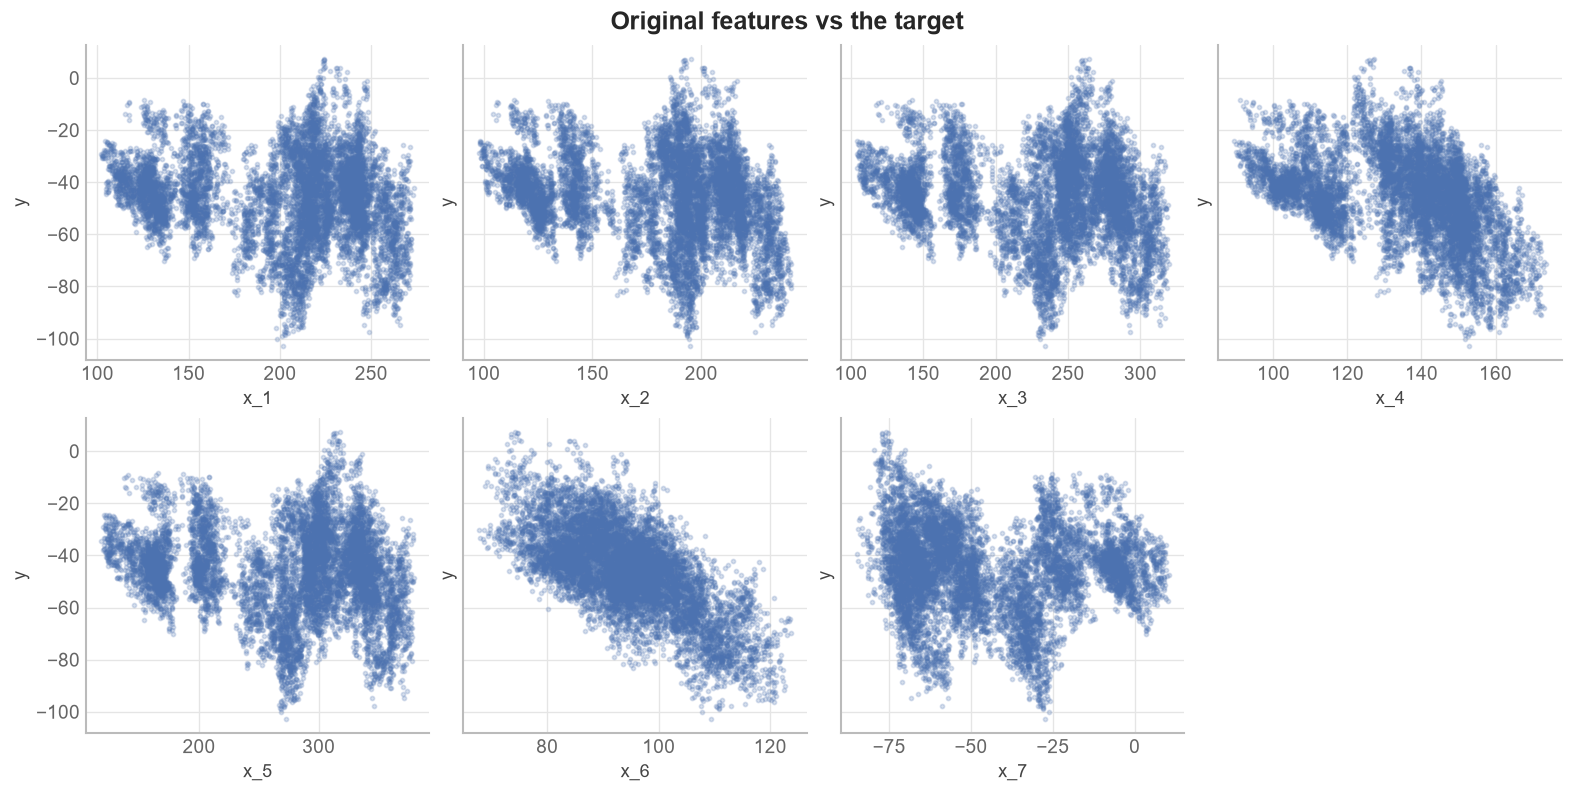

In [4]:
fig, axes = plt.subplots(2, 4, figsize=(13, 6.5), sharey=True)
for ax, col in zip(axes.flat, features):
    ax.scatter(data[col], data["y"], alpha=0.22, s=6, rasterized=True)
    ax.set(xlabel=col, ylabel="y")
axes.flat[-1].axis("off")
fig.suptitle("Original features vs the target", fontweight="bold")
plt.show()

Some of these features look more useful than others, however, I would be careful about drawing conclusions from these plots alone. A feature may not tell us much on its own, but could still be useful in combination with another feature.

To get a better idea of this, I would look at the correlations between the columns.

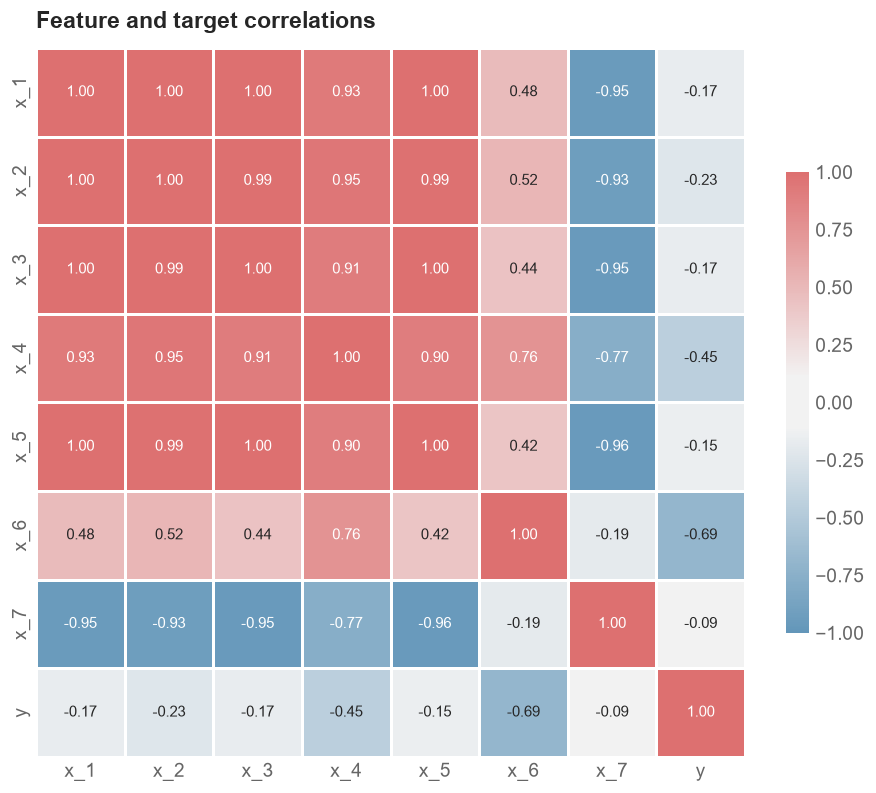

In [5]:
corr = data[features + ["y"]].corr()
fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(
    corr, cmap=sns.diverging_palette(235, 12, s=60, l=60, sep=30, as_cmap=True),
    vmin=-1, vmax=1, center=0, annot=True, fmt=".2f",
    annot_kws={"size": 9}, square=True, linewidths=0.8, linecolor="white",
    cbar_kws={"shrink": 0.65}, ax=ax,
)
ax.set_title("Feature and target correlations")
ax.grid(False)
plt.show()

Here we can see that `x_1`, `x_2`, `x_3`, and `x_5` are very highly correlated. This can cause problems if we fit our model by directly inverting the matrix in the normal equation. It also suggests that these features contain quite similar information.

However, that does not mean we should simply remove them. The difference between two features that move together could still tell us something about the target. We will come back to this after fitting a simple model.

Before doing that, there is one other plot I would recommend looking at.

### **1 - Does the order of the data matter?**

Given this data has no real-world labels or anything that tells us whether it follows a time series, I would also plot some of the columns against the row index. This lets us see whether neighbouring observations look related, which is something the scatterplots above do not tell us.

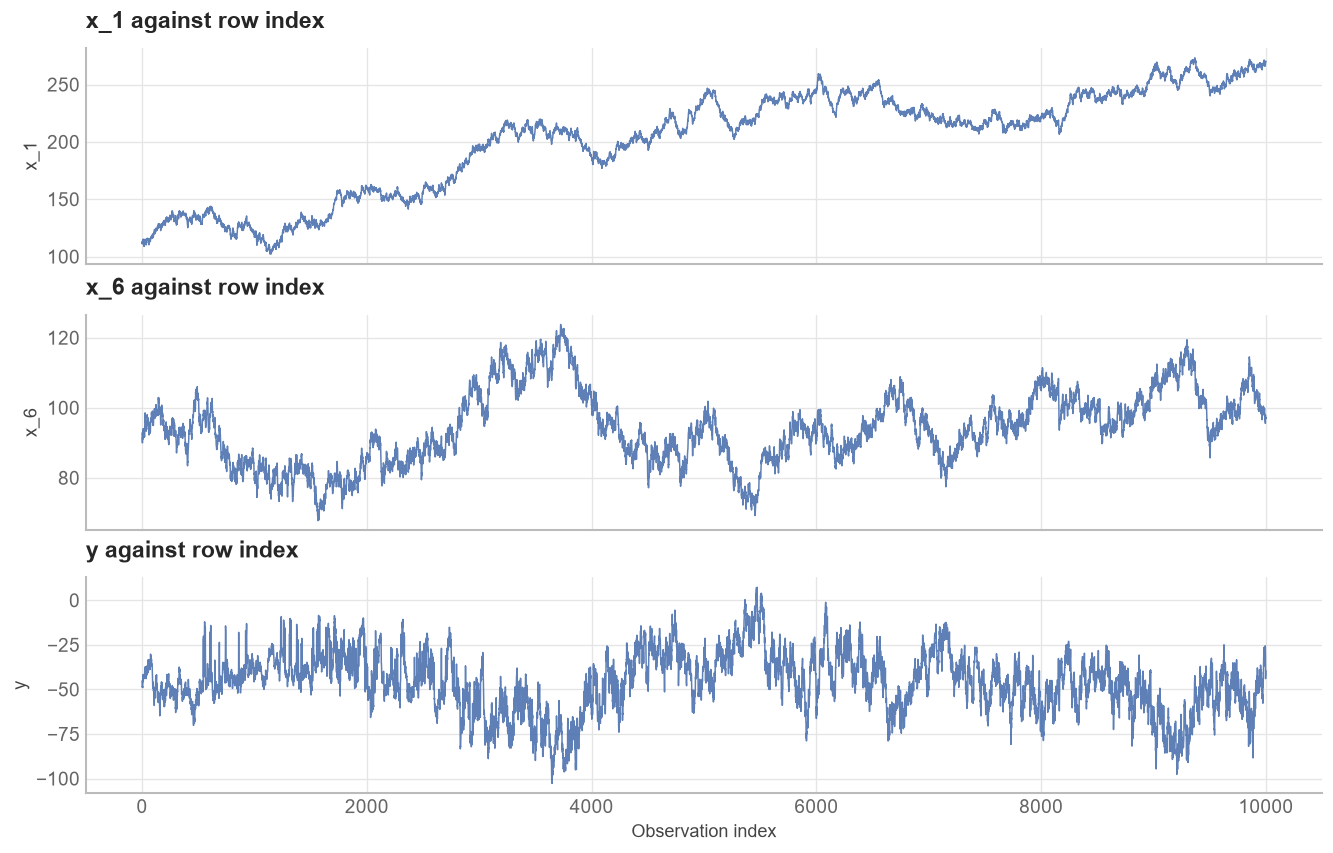

In [6]:
fig, axes = plt.subplots(3, 1, figsize=(11, 7), sharex=True)
for ax, col in zip(axes, ["x_1", "x_6", "y"]):
    ax.plot(data.index, data[col], lw=0.9, alpha=0.9)
    ax.set(ylabel=col, title=f"{col} against row index")
axes[-1].set_xlabel("Observation index")
plt.show()

Here the features change quite smoothly over long stretches of observations. The target also has some structure. I would take this as a reason to investigate whether earlier observations can help us predict later ones, however, it does not tell us that the index is a timestamp.

This also affects how I would split the data. With a random split, we could end up training and testing on neighbouring observations that are very similar. For this walkthrough I will use the first part for training, the next part for validation, and the final part for testing.

We will use the validation set to compare our modelling choices. I will leave the test performance until the end, so that we are not choosing features based on how well they work on the test set.

In [7]:
# Leave a little history at the beginning so we can investigate lags later.
# The split boundaries refer to original row indices.
train_rows = np.arange(26, 6500)
valid_rows = np.arange(6500, 8250)
test_rows = np.arange(8250, len(data))

y = data["y"].to_numpy()
X_raw = data[features].to_numpy()

print(f"Training: {len(train_rows):,} rows")
print(f"Validation: {len(valid_rows):,} rows")
print(f"Final test: {len(test_rows):,} rows (not used for feature selection)")

Training: 6,474 rows
Validation: 1,750 rows
Final test: 1,750 rows (not used for feature selection)


### **2 - Implementing a simple linear model**

Here I am starting with a linear regression class similar to the one from the exercise. There are two details I would like to point out.

First, I use `np.linalg.lstsq` to fit the parameters. This solves the least-squares problem without directly inverting $Z^TZ$, which is useful given how correlated some of our features are.

Second, I construct the basis functions before normalising the columns. Later we will add squares and products of features, and each of those new columns should be normalised too. The means and standard deviations are calculated from the training data and then reused when making predictions.

I will first compare models using `x_6`, then `x_4` and `x_6`, and finally all seven features. This gives us a starting point for judging whether the changes we make later are useful.

In [8]:
class Regression():
    def __init__(self):
        self.theta = None
        self.normalisation_means = None
        self.normalisation_stds = None
        self.eps = 1e-6  # Small constant to avoid division by zero

    def construct_design_matrix(self, X):
        X = np.asarray(X, dtype=float)
        # Add a column of ones for the intercept term
        return np.hstack((np.ones((X.shape[0], 1)), X))

    def normalise(self, X):
        # Only calculate the mean and std during fitting
        if self.normalisation_means is None or self.normalisation_stds is None:
            self.normalisation_means = X.mean(axis=0)
            self.normalisation_stds = X.std(axis=0)
        return (X - self.normalisation_means) / (self.normalisation_stds + self.eps)

    def _prepare(self, X):
        Z = self.construct_design_matrix(X)
        # The intercept is not normalised
        return np.column_stack((Z[:, 0], self.normalise(Z[:, 1:])))

    def fit(self, X, y):
        self.normalisation_means = None
        self.normalisation_stds = None
        Z = self._prepare(X)
        # Least squares is more stable than explicitly inverting Z.T @ Z
        self.theta = np.linalg.lstsq(Z, np.asarray(y), rcond=None)[0]
        return self

    def predict(self, X):
        if self.theta is None:
            raise ValueError("Fit the model before making predictions.")
        Z = self._prepare(X)
        return Z @ self.theta

In [9]:
# A small helper so that every model is compared on exactly the same split.
results = []

def mse(y_true, y_pred):
    return np.mean((y_true - y_pred) ** 2)

def evaluate(name, model, X, record=True):
    model.fit(X[train_rows], y[train_rows])
    train_mse = mse(y[train_rows], model.predict(X[train_rows]))
    valid_mse = mse(y[valid_rows], model.predict(X[valid_rows]))
    if record:
        results.append({"Model": name, "Train MSE": train_mse,
                        "Validation MSE": valid_mse})
    print(f"{name}: train MSE = {train_mse:.3f}, validation MSE = {valid_mse:.3f}")
    return model

model_x6 = evaluate("Linear: x_6", Regression(), data[["x_6"]].to_numpy())
model_two = evaluate("Linear: x_4, x_6", Regression(), data[["x_4", "x_6"]].to_numpy())
model_all = evaluate("Linear: all seven", Regression(), X_raw)
display(pd.DataFrame(results).round(3))

Linear: x_6: train MSE = 157.681, validation MSE = 124.517
Linear: x_4, x_6: train MSE = 150.914, validation MSE = 116.781
Linear: all seven: train MSE = 55.704, validation MSE = 57.469


,Model,Train MSE,Validation MSE
0,Linear: x_6,157.681,124.517
1,"Linear: x_4, x_6",150.914,116.781
2,Linear: all seven,55.704,57.469


### **2a - Trying nonlinear functions of `x_4`**

In the scatterplot for `x_4`, the points are concentrated in two regions. One thing I would try here is giving the model more flexibility in how it uses `x_4`. I will compare adding a squared term with adding a few Gaussian radial basis functions (RBFs), while keeping `x_4` and `x_6` as the linear inputs.

Each RBF gives us an extra feature that is largest near a particular value of `x_4` and gets smaller further away. Here I choose five centres using the training values of `x_4`. The point of this comparison is to see whether these extra functions improve on the linear model using the same two inputs.

In [10]:
class RegressionQuadratic(Regression):
    def construct_design_matrix(self, X):
        X = np.asarray(X, dtype=float)
        return np.column_stack((np.ones(len(X)), X, X[:, 0] ** 2))


class RegressionRBF(Regression):
    def __init__(self, centres, width):
        super().__init__()
        self.centres = np.asarray(centres)
        self.width = width

    def construct_design_matrix(self, X):
        X = np.asarray(X, dtype=float)
        x4 = X[:, [0]]
        rbf = np.exp(-0.5 * ((x4 - self.centres) / self.width) ** 2)
        return np.column_stack((np.ones(len(X)), X, rbf))


X_two = data[["x_4", "x_6"]].to_numpy()
rbf_centres = np.quantile(X_two[train_rows, 0], [0.05, 0.25, 0.50, 0.75, 0.95])
m_quad = evaluate("Quadratic: x_4 and x_6", RegressionQuadratic(), X_two)
m_rbf = evaluate("RBF: x_4 and x_6", RegressionRBF(rbf_centres, width=3.0), X_two)

display(pd.DataFrame(results).round(3))

Quadratic: x_4 and x_6: train MSE = 147.607, validation MSE = 114.646
RBF: x_4 and x_6: train MSE = 146.872, validation MSE = 112.501


,Model,Train MSE,Validation MSE
0,Linear: x_6,157.681,124.517
1,"Linear: x_4, x_6",150.914,116.781
2,Linear: all seven,55.704,57.469
3,Quadratic: x_4 and x_6,147.607,114.646
4,RBF: x_4 and x_6,146.872,112.501


Both additions improve validation performance slightly compared with the linear model using `x_4` and `x_6`. However, the linear model using all seven features still performs much better.

What I would take from this is that there is useful information in the other features. Before trying more complicated functions of `x_4`, I would look at how we could make better use of that information.

We now have a few models to compare against. The model using all seven features is doing best so far, but it still only uses a linear combination of the original columns.

Here I would go back to the highly correlated features and look at them together. I would like to see whether there is a relationship that our current model cannot capture.

### **3 - Looking at features together**

Below I have plotted a few pairs of features against each other and coloured the points by the target. This lets us see both how the inputs move together and how the target changes across the plot.

For the highly correlated pairs, I would look for whether the colour changes across the narrow band of points. If it does, the difference between the two features may be useful.

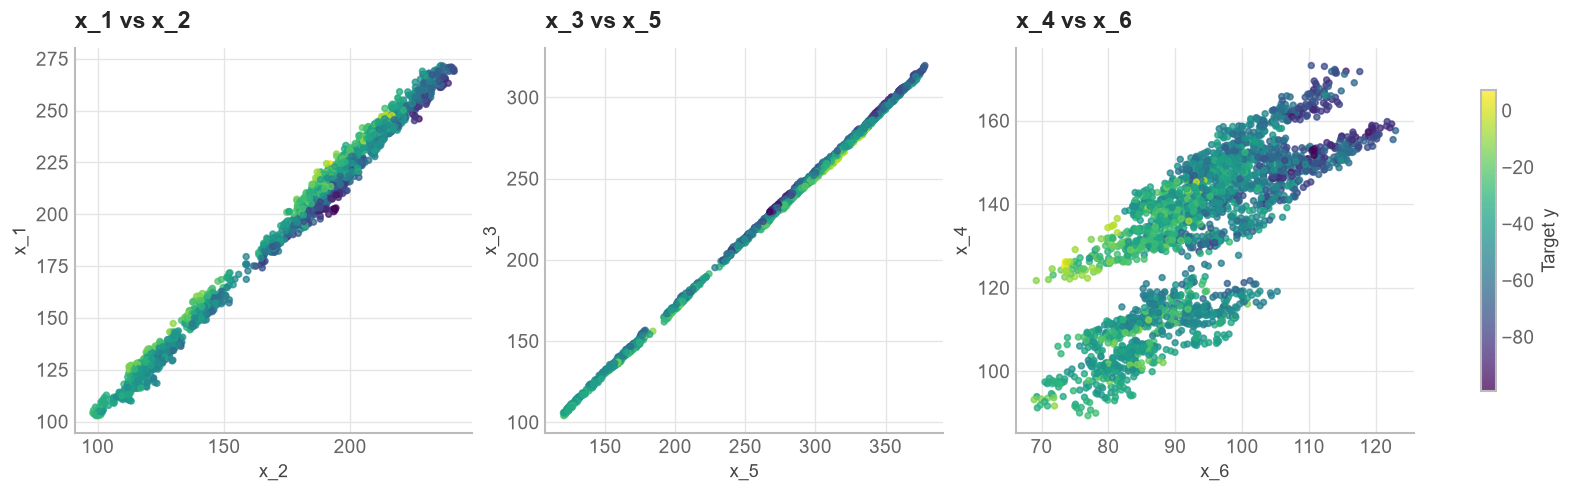

In [11]:
sample = data.sample(n=2500, random_state=42)
pairs = [("x_1", "x_2"), ("x_3", "x_5"), ("x_4", "x_6")]
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, (a, b) in zip(axes, pairs):
    sc = ax.scatter(sample[b], sample[a], c=sample["y"], cmap="viridis",
                    s=12, alpha=0.75, rasterized=True)
    ax.set(xlabel=b, ylabel=a, title=f"{a} vs {b}")
fig.colorbar(sc, ax=list(axes), label="Target y", shrink=0.78)
plt.show()

To look more closely at these differences, we can subtract a scaled version of one feature from the other:

$$d_{a,b}=x_a-cx_b.$$

We need the scale $c$ because the two features have different magnitudes. For `x_1` and `x_2`, I will start with the ratio of their training means. For `x_3` and `x_5`, I will use the slope of a line fitted between their training values.

These are just starting choices. If the differences turn out to be useful, we can investigate the scales further using the validation set.

Initial x_1/x_2 scaling: 1.10
Initial x_3/x_5 scaling: 0.81


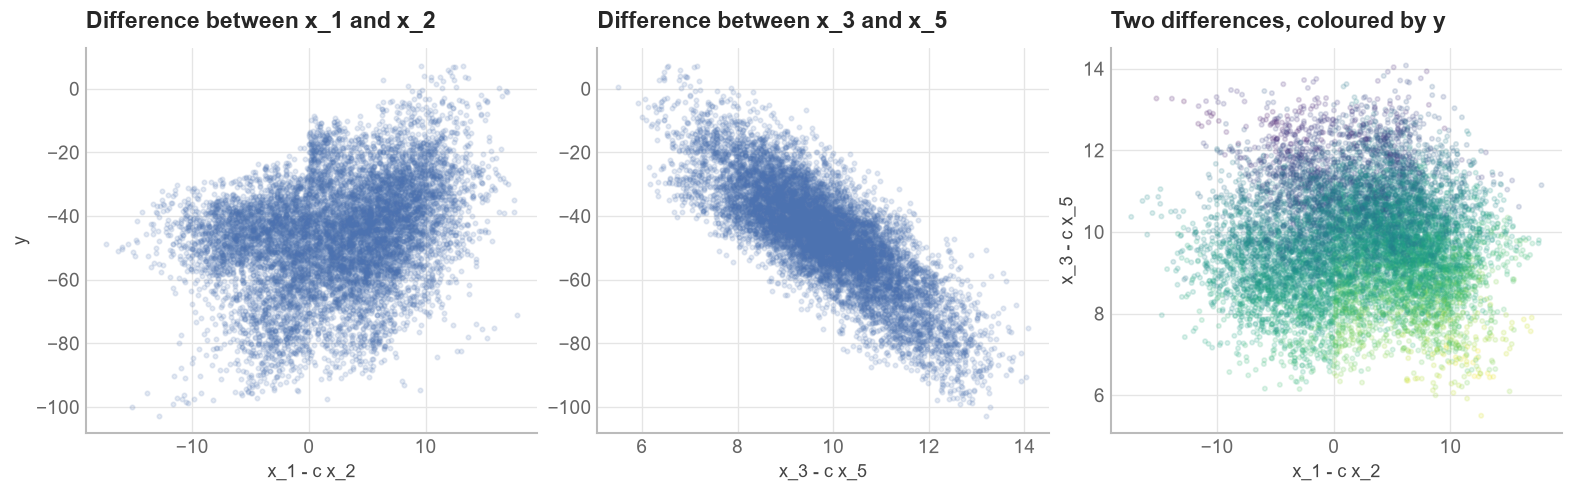

In [12]:
ratio_12 = round(data.loc[train_rows, "x_1"].mean() /
                 data.loc[train_rows, "x_2"].mean(), 2)
ratio_35 = round(np.polyfit(data.loc[train_rows, "x_5"],
                            data.loc[train_rows, "x_3"], 1)[0], 2)

print(f"Initial x_1/x_2 scaling: {ratio_12:.2f}")
print(f"Initial x_3/x_5 scaling: {ratio_35:.2f}")

d12 = data["x_1"] - ratio_12 * data["x_2"]
d35 = data["x_3"] - ratio_35 * data["x_5"]

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
axes[0].scatter(d12, data["y"], alpha=0.15, s=7, rasterized=True)
axes[0].set(xlabel="x_1 - c x_2", ylabel="y", title="Difference between x_1 and x_2")
axes[1].scatter(d35, data["y"], alpha=0.15, s=7, rasterized=True)
axes[1].set(xlabel="x_3 - c x_5", title="Difference between x_3 and x_5")
axes[2].scatter(d12, d35, c=data["y"], cmap="viridis", alpha=0.16, s=7, rasterized=True)
axes[2].set(xlabel="x_1 - c x_2", ylabel="x_3 - c x_5", title="Two differences, coloured by y")
plt.show()

There is still quite a lot of scatter here, however, these plots give us a different view of the data. I would use them to suggest a few features to try:

- A squared term for the first difference, so the model can capture a curved relationship with the target.
- Products of the second difference with `x_4` and `x_6`, so the effect of the difference can depend on the values of these other features.

One thing to keep in mind is that adding the difference on its own would not give our linear model anything new. It is already a linear combination of two columns we have. Squaring it or multiplying it by another feature is what allows the model to express a different relationship.

These plots do not prove that either addition will help. We need to fit the models and compare their validation performance.

### **4 - Adding basis functions to the model**

Here I have kept the feature construction inside `construct_design_matrix`, as in the regression class from the exercise. The class below extends our simple model, so we can change the basis functions without rewriting the fitting and prediction methods.

I have included the options we will use later in the walkthrough as well. For now we will only try the squared difference and the products with `x_4` and `x_6`. The input function also supplies earlier values of `x_3` and `x_5`, which we will use in the next section.

In [13]:
def make_inputs(lag=0):
    """Original seven features and earlier values of x_3 and x_5.

    The first 26 rows are omitted from training/evaluation for all models,
    so the comparison remains aligned when we try lags up to 25.
    """
    return np.column_stack([
        X_raw,
        data["x_3"].shift(lag).to_numpy(),
        data["x_5"].shift(lag).to_numpy(),
    ])


class FeatureRegression(Regression):
    def __init__(self, ratio_12, ratio_35, x7_centre, *,
                 square=False, interactions=False, lag_interactions=False,
                 regime=False, periodic=False, frequency=0.5):
        super().__init__()
        self.ratio_12 = ratio_12
        self.ratio_35 = ratio_35
        self.x7_centre = x7_centre
        self.square = square
        self.interactions = interactions
        self.lag_interactions = lag_interactions
        self.regime = regime
        self.periodic = periodic
        self.frequency = frequency

    def construct_design_matrix(self, X):
        X = np.asarray(X, dtype=float)
        x1, x2, x3, x4, x5, x6, x7 = X[:, :7].T
        x3_lag, x5_lag = X[:, 7:].T

        # Start with the seven ordinary linear terms
        columns = [X[:, :7]]
        d12 = x1 - self.ratio_12 * x2
        d35 = x3 - self.ratio_35 * x5

        if self.square:
            columns.append(d12[:, None] ** 2)

        if self.interactions:
            columns.extend([(d35 * x4)[:, None], (d35 * x6)[:, None]])

        if self.lag_interactions:
            d35_lag = x3_lag - self.ratio_35 * x5_lag
            columns.extend([(d35_lag * x4)[:, None], (d35_lag * x6)[:, None]])

        if self.regime:
            # Ask if the relationship with x_7 depends on the sign of d12
            is_positive = (d12 > 0).astype(float)
            columns.extend([is_positive[:, None],
                            (is_positive * (x7 - self.x7_centre))[:, None]])

        if self.periodic:
            columns.append(np.sin(self.frequency * d12)[:, None])

        return np.column_stack([np.ones(len(X)), *columns])


x7_centre = float(data.loc[train_rows, "x_7"].mean())

def model_with(**kwargs):
    return FeatureRegression(ratio_12, ratio_35, x7_centre, **kwargs)

X_initial = make_inputs()
m_sq = evaluate("All seven + squared difference", model_with(square=True), X_initial)
m_inter = evaluate("+ pairwise interactions", model_with(square=True, interactions=True), X_initial)
display(pd.DataFrame(results).round(3))

All seven + squared difference: train MSE = 54.687, validation MSE = 60.256
+ pairwise interactions: train MSE = 52.679, validation MSE = 59.586


,Model,Train MSE,Validation MSE
0,Linear: x_6,157.681,124.517
1,"Linear: x_4, x_6",150.914,116.781
2,Linear: all seven,55.704,57.469
3,Quadratic: x_4 and x_6,147.607,114.646
4,RBF: x_4 and x_6,146.872,112.501
5,All seven + squared difference,54.687,60.256
6,+ pairwise interactions,52.679,59.586


Here the squared difference makes the validation error slightly worse. Adding the products brings it down a little, but we are still doing worse than the linear model using all seven features.

This is why I would like you to connect your plots to experiments with the model. A plot can give us a reason to try a feature, however, we still need to check whether it helps.

There is also something from the plot against the row index that we have not used yet: neighbouring observations appear to be related.

### **5 - Investigating delayed relationships**

Given what we saw in the row-index plots, I would also investigate whether values from earlier rows can help predict the target. Here I will try using an earlier difference between `x_3` and `x_5` in the products with the current values of `x_4` and `x_6`.

This is one possible experiment, rather than something we can conclude directly from the earlier plots. I will try delays from 0 to 25 observations and compare the validation errors, keeping the other features the same. A delay of 0 uses the current row.

Best lag on validation data: 11


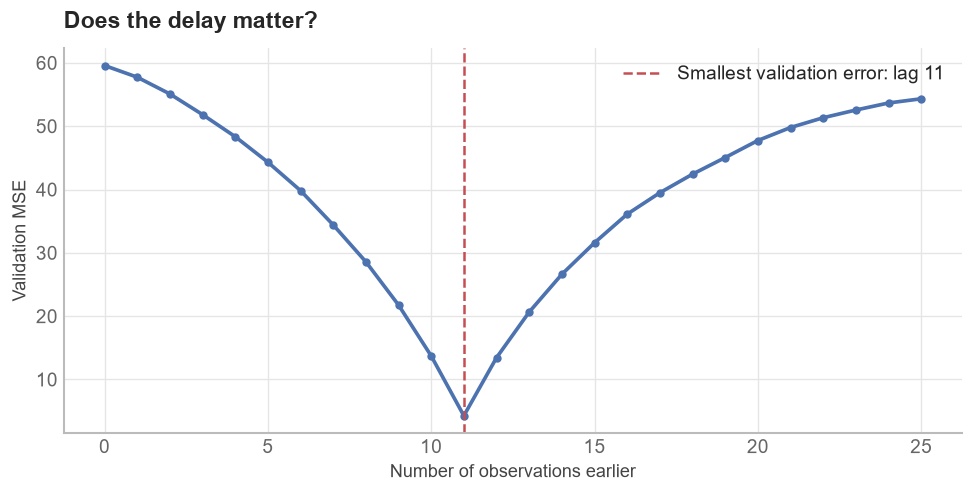

In [14]:
lag_values = np.arange(0, 26)
lag_errors = []
for lag in lag_values:
    candidate = model_with(square=True, interactions=True, lag_interactions=True)
    X_candidate = make_inputs(lag=lag)
    candidate.fit(X_candidate[train_rows], y[train_rows])
    lag_errors.append(mse(y[valid_rows], candidate.predict(X_candidate[valid_rows])))

best_lag = int(lag_values[np.argmin(lag_errors)])
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(lag_values, lag_errors, marker="o", ms=4)
ax.axvline(best_lag, color=palette[3], ls="--", lw=1.5,
           label=f"Smallest validation error: lag {best_lag}")
ax.set(xlabel="Number of observations earlier", ylabel="Validation MSE",
       title="Does the delay matter?")
ax.legend()
plt.show()
print(f"Best lag on validation data: {best_lag}")

The validation error is lowest at a delay of 11 observations, and it is quite a clear minimum. This suggests that the earlier values contain useful information for this model.

The reasoning here started with the structure in the row-index plot, then the differences between correlated features, and finally an experiment combining these ideas. We did not need to know how the data was generated to try this, however, we did need to test the idea.

+ lagged interactions: train MSE = 15.526, validation MSE = 4.271


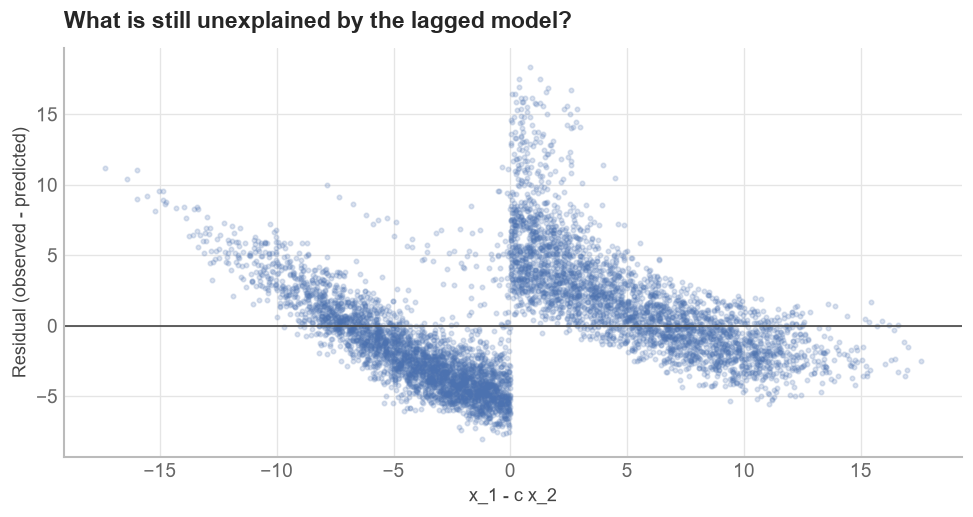

In [15]:
X_best = make_inputs(lag=best_lag)
m_lag = evaluate("+ lagged interactions", model_with(
    square=True, interactions=True, lag_interactions=True), X_best)

# Residuals can be more informative than the original target at this point.
train_residual = y[train_rows] - m_lag.predict(X_best[train_rows])

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.scatter(d12.iloc[train_rows], train_residual, alpha=0.20, s=7, rasterized=True)
ax.axhline(0, color="#444444", lw=1)
ax.set(xlabel="x_1 - c x_2", ylabel="Residual (observed - predicted)",
       title="What is still unexplained by the lagged model?")
plt.show()

At this point I would start looking at the residuals, which are the observed target values minus the model's predictions. We have explained some of the larger variation, so the remaining relationships may be easier to see here than in the original target plots.

The plot above shows the residuals against the first difference. I would also look at whether other features behave differently depending on this difference. One candidate is `x_7`, which did not look especially useful in the original scatterplot.

### **6 - Does the relationship with `x_7` change across regions?**

Here I will split the training observations according to whether the difference $d_{12}=x_1-cx_2$ is positive or not. Then I will plot the residuals against `x_7` in each group.

What I am looking for is whether `x_7` has a different relationship with the residuals in the two groups. Our current model uses the same coefficient for `x_7` everywhere, so it would not capture this.

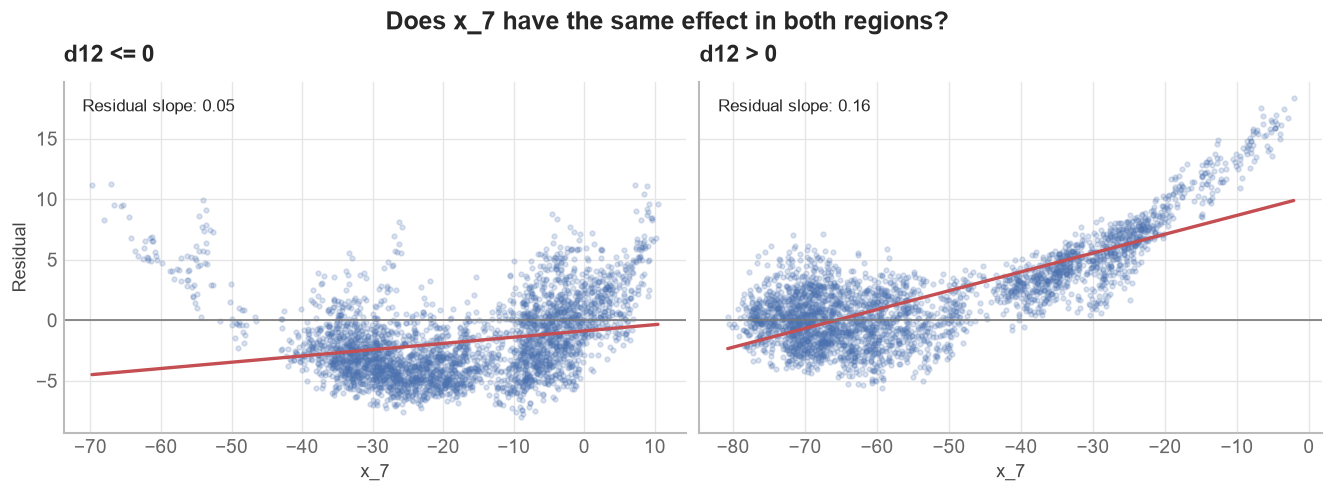

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, positive in zip(axes, [False, True]):
    mask = (d12.iloc[train_rows].to_numpy() > 0) == positive
    vals = data["x_7"].to_numpy()[train_rows][mask]
    res = train_residual[mask]
    ax.scatter(vals, res, alpha=0.20, s=8, rasterized=True)
    slope, intercept = np.polyfit(vals, res, 1)
    grid = np.linspace(vals.min(), vals.max(), 100)
    ax.plot(grid, slope * grid + intercept, c=palette[3], lw=2)
    ax.axhline(0, color="#777777", lw=1)
    ax.set(xlabel="x_7", title="d12 > 0" if positive else "d12 <= 0")
    ax.text(.03, .95, f"Residual slope: {slope:.2f}", transform=ax.transAxes,
            va="top", fontsize=10)
axes[0].set_ylabel("Residual")
fig.suptitle("Does x_7 have the same effect in both regions?", fontweight="bold")
plt.show()

The fitted lines suggest that the relationship with `x_7` differs between the two groups. One way to represent this is to add an indicator that is 1 when $d_{12}>0$ and 0 otherwise, along with the product of that indicator and `x_7`.

This allows both the intercept and the coefficient of `x_7` to change between the groups. We can still fit the model in the same way, as these are just extra columns in the design matrix.

In [17]:
m_regime = evaluate("+ conditional x_7 term", model_with(
    square=True, interactions=True, lag_interactions=True, regime=True), X_best)
display(pd.DataFrame(results).round(3))

+ conditional x_7 term: train MSE = 3.667, validation MSE = 4.644


,Model,Train MSE,Validation MSE
0,Linear: x_6,157.681,124.517
1,"Linear: x_4, x_6",150.914,116.781
2,Linear: all seven,55.704,57.469
3,Quadratic: x_4 and x_6,147.607,114.646
4,RBF: x_4 and x_6,146.872,112.501
5,All seven + squared difference,54.687,60.256
6,+ pairwise interactions,52.679,59.586
7,+ lagged interactions,15.526,4.271
8,+ conditional x_7 term,3.667,4.644


The conditional term reduces the training error quite a lot, however, the validation error is slightly worse. I would not take the training improvement alone as evidence that we have a better model.

Before drawing a conclusion, I would also revisit the scale used in the `x_3`/`x_5` difference. We chose it from the slope between the inputs, which does not necessarily give us the best scale for predicting `y`.

Here I will keep the conditional term while trying a small range of scales around our original estimate. We can then compare the result with the earlier models.

Chosen scale using validation data: 0.830


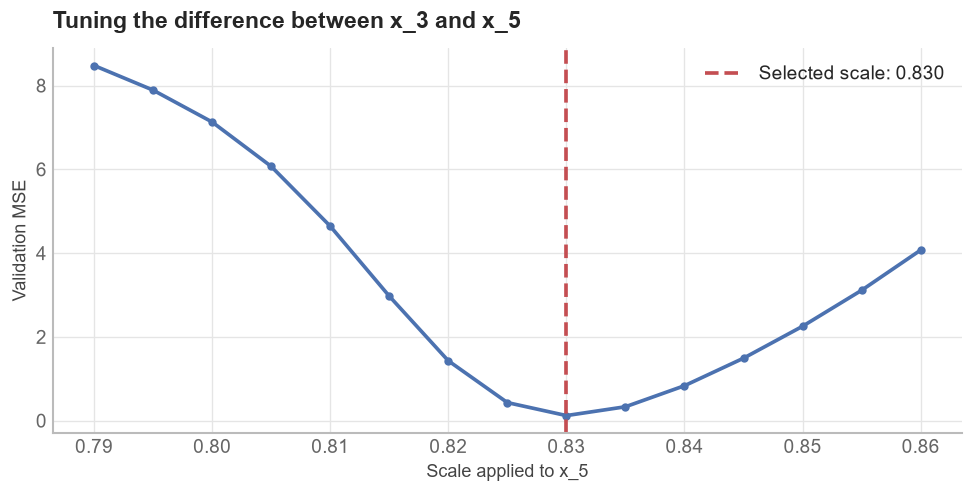

In [18]:
# Coarse but interpretable search around the scale suggested by x_3 vs x_5.
ratio_candidates = np.round(np.arange(0.79, 0.861, 0.005), 3)
ratio_errors = []
for ratio in ratio_candidates:
    candidate = FeatureRegression(
        ratio_12, ratio, x7_centre,
        square=True, interactions=True, lag_interactions=True, regime=True
    )
    candidate.fit(X_best[train_rows], y[train_rows])
    ratio_errors.append(mse(y[valid_rows], candidate.predict(X_best[valid_rows])))

ratio_35 = float(ratio_candidates[np.argmin(ratio_errors)])
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(ratio_candidates, ratio_errors, marker="o", ms=4)
ax.axvline(ratio_35, color=palette[3], ls="--", label=f"Selected scale: {ratio_35:.3f}")
ax.set(xlabel="Scale applied to x_5", ylabel="Validation MSE",
       title="Tuning the difference between x_3 and x_5")
ax.legend()
plt.show()
print(f"Chosen scale using validation data: {ratio_35:.3f}")

Here a small change in the scale makes quite a large difference to validation performance. This is useful to see: once we use products and delayed values, the way we combine these correlated inputs matters a lot.

I will now fit the model with the selected scale and look at the residuals again. Alongside the scatterplot, I have grouped observations with similar values of the first difference and plotted their mean residual. This can make smaller patterns easier to see.

+ tuned difference scale: train MSE = 0.110, validation MSE = 0.121


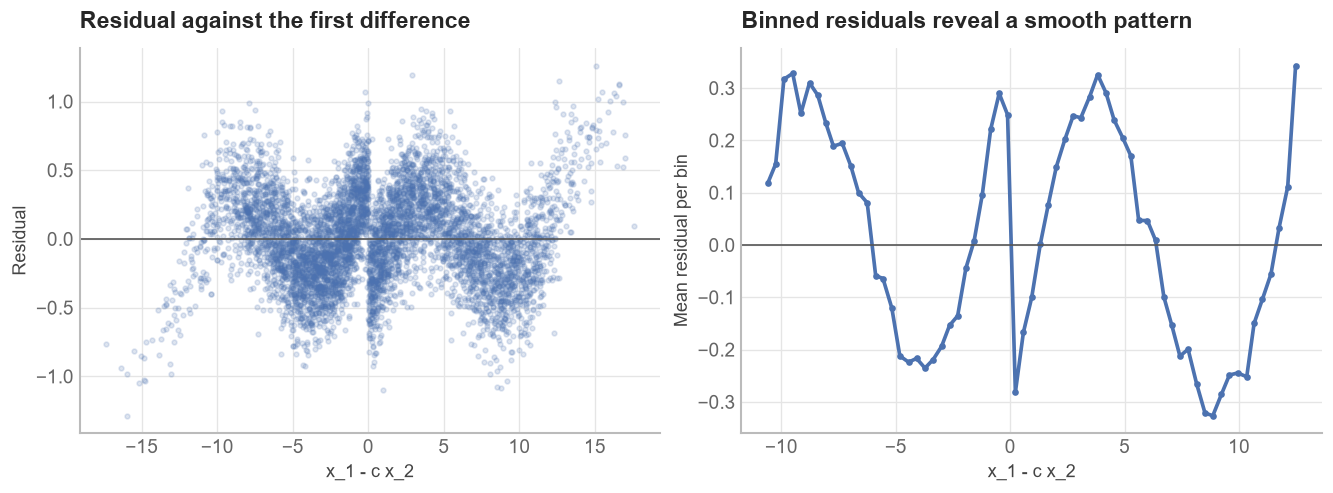

In [19]:
m_tuned = evaluate("+ tuned difference scale", model_with(
    square=True, interactions=True, lag_interactions=True, regime=True), X_best)

residual = y[train_rows] - m_tuned.predict(X_best[train_rows])
d12_train = d12.iloc[train_rows].to_numpy()

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(d12_train, residual, s=8, alpha=0.18, rasterized=True)
axes[0].axhline(0, c="#555555", lw=1)
axes[0].set(xlabel="x_1 - c x_2", ylabel="Residual", title="Residual against the first difference")

# Bin the same observations so small, systematic patterns are easier to see.
bins = np.linspace(np.percentile(d12_train, 1), np.percentile(d12_train, 99), 70)
which = np.digitize(d12_train, bins)
centres, averages = [], []
for j in range(1, len(bins)):
    mask = which == j
    if mask.sum() >= 20:
        centres.append(np.mean(d12_train[mask]))
        averages.append(np.mean(residual[mask]))
axes[1].plot(centres, averages, marker="o", ms=3)
axes[1].axhline(0, c="#555555", lw=1)
axes[1].set(xlabel="x_1 - c x_2", ylabel="Mean residual per bin",
            title="Binned residuals reveal a smooth pattern")
plt.show()

### **7 - Looking at the remaining pattern**

The binned residuals suggest a small repeating pattern in the first difference. One function I would try for this is a sine function.

We do not know which frequency to use, so I will try a small range and compare the validation errors. As with the earlier basis functions, I would only keep this addition if it improves the model.

Chosen frequency: 0.50


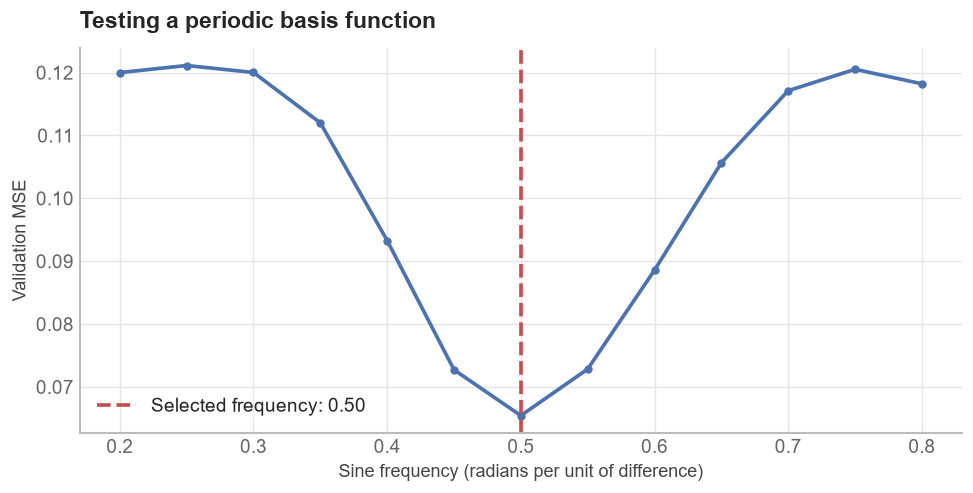

In [20]:
frequencies = np.round(np.arange(0.2, 0.81, 0.05), 2)
frequency_errors = []
for freq in frequencies:
    candidate = model_with(square=True, interactions=True, lag_interactions=True,
                           regime=True, periodic=True, frequency=float(freq))
    candidate.fit(X_best[train_rows], y[train_rows])
    frequency_errors.append(mse(y[valid_rows], candidate.predict(X_best[valid_rows])))

best_frequency = float(frequencies[np.argmin(frequency_errors)])
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(frequencies, frequency_errors, marker="o", ms=4)
ax.axvline(best_frequency, color=palette[3], ls="--",
           label=f"Selected frequency: {best_frequency:.2f}")
ax.set(xlabel="Sine frequency (radians per unit of difference)",
       ylabel="Validation MSE", title="Testing a periodic basis function")
ax.legend()
plt.show()
print(f"Chosen frequency: {best_frequency:.2f}")

In [21]:
m_periodic = evaluate("+ periodic basis function", model_with(
    square=True, interactions=True, lag_interactions=True,
    regime=True, periodic=True, frequency=best_frequency), X_best)

display(pd.DataFrame(results).round(3))

+ periodic basis function: train MSE = 0.062, validation MSE = 0.065


,Model,Train MSE,Validation MSE
0,Linear: x_6,157.681,124.517
1,"Linear: x_4, x_6",150.914,116.781
2,Linear: all seven,55.704,57.469
3,Quadratic: x_4 and x_6,147.607,114.646
4,RBF: x_4 and x_6,146.872,112.501
5,All seven + squared difference,54.687,60.256
6,+ pairwise interactions,52.679,59.586
7,+ lagged interactions,15.526,4.271
8,+ conditional x_7 term,3.667,4.644
9,+ tuned difference scale,0.110,0.121


The sine term gives a further improvement in validation performance. It is smaller than the improvement from tuning the difference scale, but it does help explain some of what remained in the residuals.

We have now made several choices using the same validation set. This is useful for showing the iterative process, however, we still need the final test set to check how the selected model performs on observations we have not used for these decisions.

### **8 - Comparing the models and checking generalisation**

Here I would look back over the validation results from each stage. This lets us see which changes helped and which did not. Adding more features does not automatically give us a better model, as we saw with some of the earlier comparisons.

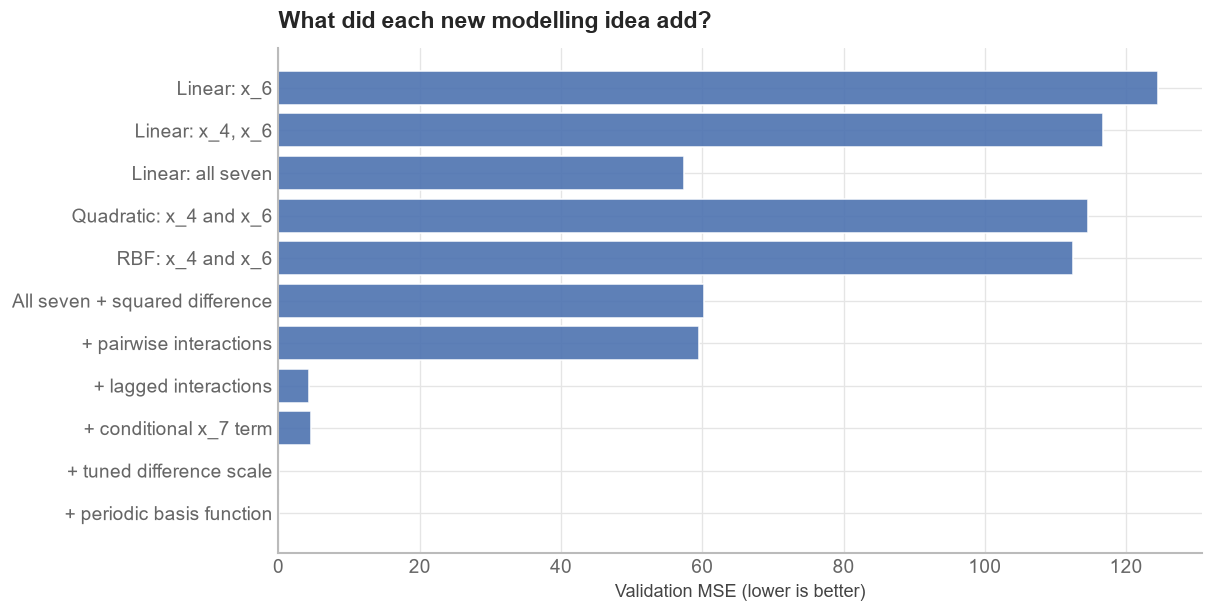

,Model,Train MSE,Validation MSE
0,Linear: x_6,157.6811,124.5170
1,"Linear: x_4, x_6",150.9139,116.7812
2,Linear: all seven,55.7045,57.4690
3,Quadratic: x_4 and x_6,147.6068,114.6459
4,RBF: x_4 and x_6,146.8721,112.5011
5,All seven + squared difference,54.6867,60.2557
6,+ pairwise interactions,52.6785,59.5861
7,+ lagged interactions,15.5260,4.2711
8,+ conditional x_7 term,3.6669,4.6438
9,+ tuned difference scale,0.1102,0.1205


In [22]:
summary = pd.DataFrame(results)
fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(summary["Model"], summary["Validation MSE"], color=palette[0], alpha=0.9)
ax.invert_yaxis()
ax.set(xlabel="Validation MSE (lower is better)", title="What did each new modelling idea add?")
plt.show()
display(summary.round(4))

The model with the sine term has the lowest validation error of the models we tried, so I will use that as the final model. I will refit it using the training and validation observations together, keeping the feature choices, delay, scale, and frequency fixed. Then I will calculate the test error.

For a larger project I would also compare performance across several validation periods. Here we have used one split to walk through the process of analysing the data and improving the model.

Test MSE: 0.0601
Test R^2: 0.99970


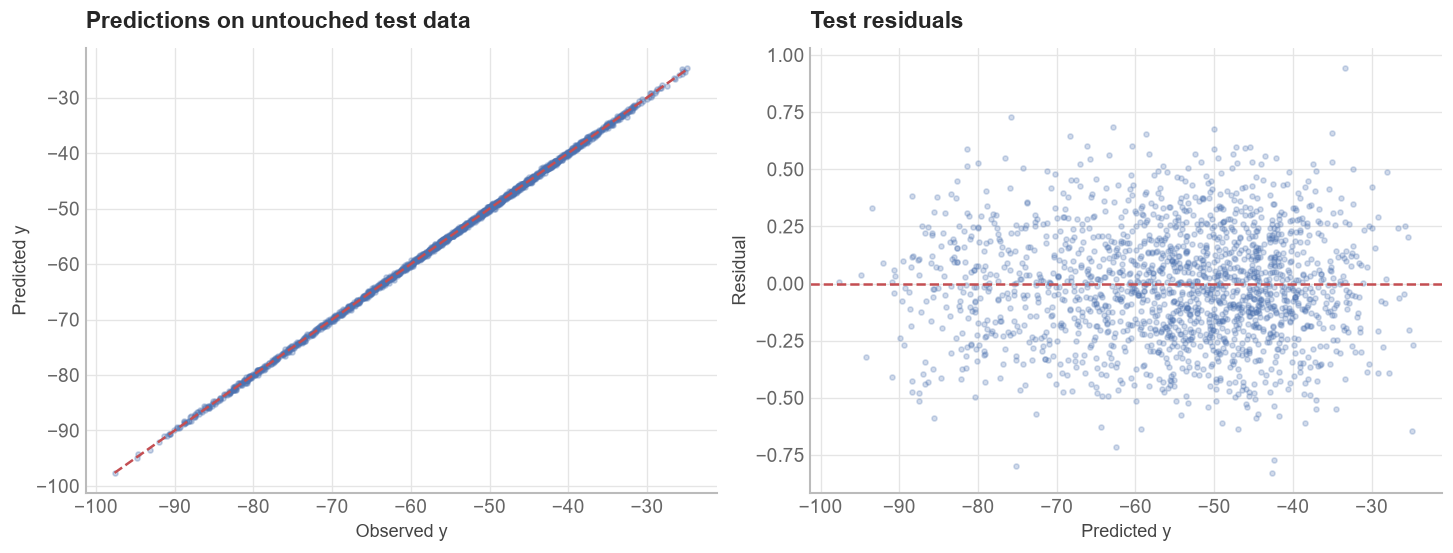

In [23]:
# Use the model with the lowest validation error.
final_model = model_with(
    square=True, interactions=True, lag_interactions=True, regime=True,
    periodic=True, frequency=best_frequency,
)

# Refit on training + validation. No hyperparameters are changed using the test set.
train_valid_rows = np.concatenate([train_rows, valid_rows])
final_model.fit(X_best[train_valid_rows], y[train_valid_rows])
test_pred = final_model.predict(X_best[test_rows])

final_mse = mse(y[test_rows], test_pred)
final_r2 = 1 - np.sum((test_pred - y[test_rows]) ** 2) / np.sum((y[test_rows] - y[test_rows].mean()) ** 2)
print(f"Test MSE: {final_mse:.4f}")
print(f"Test R^2: {final_r2:.5f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].scatter(y[test_rows], test_pred, alpha=0.3, s=9, rasterized=True)
lo = min(y[test_rows].min(), test_pred.min())
hi = max(y[test_rows].max(), test_pred.max())
axes[0].plot([lo, hi], [lo, hi], c=palette[3], ls="--", lw=1.5)
axes[0].set(xlabel="Observed y", ylabel="Predicted y", title="Predictions on untouched test data")
axes[1].scatter(test_pred, y[test_rows] - test_pred, alpha=0.25, s=9, rasterized=True)
axes[1].axhline(0, c=palette[3], ls="--", lw=1.5)
axes[1].set(xlabel="Predicted y", ylabel="Residual", title="Test residuals")
plt.show()

### **9 - What I would like you to take away from this**

What I would like you to take away from this walkthrough is the process of looking at the data, drawing conclusions, and using those conclusions to decide what to try next. I would not expect you to have guessed these particular basis functions.

The original scatterplots gave us a starting point, however, they did not show all the useful relationships. Looking at the features together and plotting them against the row index gave us other ideas to investigate. Later, looking at the residuals helped us find relationships that were harder to see at the beginning.

For each change to the model, you should be able to explain what led you to try it and whether it improved validation performance. Some of the changes here did not help on their own, which is also a useful result.

One other thing to keep in mind is that the model remained linear in its parameters throughout. We changed the functions of the inputs in the design matrix, but we could still fit the parameters using least squares.

This does not prove that we have found the equation used to generate the data. What we have is a model that performs well on the test set and a process we can explain. If I were marking this practical, that reasoning would matter at least as much as the final MSE.